In [8]:
# notebooks/pseudo_arclength_continuation.ipynb — first cell
import numpy as np
import sys
sys.path.insert(0, '../src')
from orbits import periodicity_constraint
from cr3bp import find_lagrange_points, MU_EARTH_MOON

mu = MU_EARTH_MOON

# Your known periodic orbit
X = np.array([0.8359151258, 0.0084348855, 1.3458950464])  # [x0, vy0, T_half]

F, dF, final = periodicity_constraint(X, mu)
print("F at known orbit (should be ~0):")
print(f"  y(T_half)  = {F[0]:.2e}")
print(f"  vx(T_half) = {F[1]:.2e}")
print(f"\nFinal state: {final}")
print(f"\ndF/dX (2x3 Jacobian):")
print(dF)

# Spot-check the Jacobian against finite differences
print("\nFinite-difference check of Jacobian:")
eps = 1e-7
for j in range(3):
    Xp = X.copy(); Xp[j] += eps
    Fp, _, _ = periodicity_constraint(Xp, mu)
    fd = (Fp - F) / eps
    print(f"  column {j}: analytic={dF[:,j]}, finite-diff={fd}, "
          f"max diff={np.max(np.abs(dF[:,j] - fd)):.2e}")

F at known orbit (should be ~0):
  y(T_half)  = -4.73e-10
  vx(T_half) = 2.96e-09

Final state: [ 8.37933815e-01 -4.73335596e-10  2.95837690e-09 -8.46533964e-03]

dF/dX (2x3 Jacobian):
[[-1.43921284e+01 -1.69332731e+00 -8.46533964e-03]
 [ 8.99325280e+01  1.05826025e+01 -5.35674797e-03]]

Finite-difference check of Jacobian:
  column 0: analytic=[-14.3921284   89.93252795], finite-diff=[-14.39213886  89.93395222], max diff=1.42e-03
  column 1: analytic=[-1.69332731 10.58260246], finite-diff=[-1.69332762 10.58262077], max diff=1.83e-05
  column 2: analytic=[-0.00846534 -0.00535675], finite-diff=[-0.00846534 -0.00535675], max diff=7.34e-10


In [9]:
# notebook cell — check relative error of the Jacobian columns
print("Relative-error check of Jacobian:")
eps = 1e-7
for j in range(3):
    Xp = X.copy(); Xp[j] += eps
    Fp, _, _ = periodicity_constraint(Xp, mu)
    fd = (Fp - F) / eps
    abs_diff = np.max(np.abs(dF[:,j] - fd))
    scale = np.max(np.abs(dF[:,j]))
    rel_diff = abs_diff / scale if scale > 0 else abs_diff
    print(f"  column {j}: abs diff={abs_diff:.2e}, magnitude={scale:.2e}, "
          f"relative diff={rel_diff:.2e}")

Relative-error check of Jacobian:
  column 0: abs diff=1.42e-03, magnitude=8.99e+01, relative diff=1.58e-05
  column 1: abs diff=1.83e-05, magnitude=1.06e+01, relative diff=1.73e-06
  column 2: abs diff=7.34e-10, magnitude=8.47e-03, relative diff=8.67e-08


In [10]:
# notebook cell — test the tangent computation
from orbits import family_tangent

# Use the Jacobian from the known orbit
F, dF, final = periodicity_constraint(X, mu)
tangent = family_tangent(dF)

print(f"Tangent vector: {tangent}")
print(f"  (components correspond to [d(x0), d(vy0), d(T_half)] along the family)")
print(f"Norm (should be 1.0): {np.linalg.norm(tangent):.6f}")

# Verify it's actually in the null space: dF @ tangent should be ~0
null_check = dF @ tangent
print(f"\ndF @ tangent (should be ~0): {null_check}")
print(f"  max component: {np.max(np.abs(null_check)):.2e}")

Tangent vector: [-0.11682886  0.99284161  0.02483036]
  (components correspond to [d(x0), d(vy0), d(T_half)] along the family)
Norm (should be 1.0): 1.000000

dF @ tangent (should be ~0): [-1.21762812e-16  9.89049920e-16]
  max component: 9.89e-16


In [11]:
# notebook cell — test the predict step and see how far off the family it lands
from orbits import predict_step

ds = 0.01   # arclength step size — we'll tune this later
X_predicted = predict_step(X, tangent, ds)

print(f"Current orbit X:    {X}")
print(f"Predicted orbit:    {X_predicted}")
print(f"Step taken:         {ds} along tangent {tangent}")

# How far off the family is the prediction? Evaluate F at the predicted point.
# (It was ~0 at X; see how much the finite step knocked it off.)
F_pred, dF_pred, _ = periodicity_constraint(X_predicted, mu)
print(f"\nF at predicted point (was ~0 at current orbit):")
print(f"  y  = {F_pred[0]:.2e}")
print(f"  vx = {F_pred[1]:.2e}")
print(f"  This nonzero F is the finite-step error the corrector will fix.")

Current orbit X:    [0.83591513 0.00843489 1.34589505]
Predicted orbit:    [0.83474684 0.0183633  1.34614335]
Step taken:         0.01 along tangent [-0.11682886  0.99284161  0.02483036]

F at predicted point (was ~0 at current orbit):
  y  = 1.53e-04
  vx = -9.14e-04
  This nonzero F is the finite-step error the corrector will fix.


In [12]:
# notebook cell — test the pseudo-arclength corrector
from orbits import pseudo_arclength_correct

X_previous = X.copy()   # the known orbit is our "previous"
ds = 0.01

X_corrected = pseudo_arclength_correct(X_predicted, X_previous, tangent, ds, mu,
                                        verbose=True)

print(f"\nPredicted orbit:  {X_predicted}")
print(f"Corrected orbit:  {X_corrected}")

# Verify the corrected orbit is on the family (F ~ 0)
F_corr, _, _ = periodicity_constraint(X_corrected, mu)
print(f"\nF at corrected orbit (should be ~0):")
print(f"  y  = {F_corr[0]:.2e}")
print(f"  vx = {F_corr[1]:.2e}")

# Verify the arclength: distance along tangent from previous should be ds
arc_achieved = np.dot(X_corrected - X_previous, tangent)
print(f"\nArclength from previous orbit: {arc_achieved:.6f} (target: {ds})")

# And confirm it's a DIFFERENT orbit from where we started (we actually moved)
print(f"\nJacobi of previous: check it moved...")

    Newton iter 0: |G| = 9.138e-04
    Newton iter 1: |G| = 1.881e-06
    Newton iter 2: |G| = 5.310e-11
    Newton iter 3: |G| = 2.074e-14

Predicted orbit:  [0.83474684 0.0183633  1.34614335]
Corrected orbit:  [0.83475738 0.01836085 1.34629097]

F at corrected orbit (should be ~0):
  y  = -2.00e-15
  vx = 1.19e-14

Arclength from previous orbit: 0.010000 (target: 0.01)

Jacobi of previous: check it moved...


In [13]:
# notebook cell — compute the L1 Lyapunov family via pseudo-arclength
from orbits import compute_family_pseudo_arclength

# Start from your known orbit. March in the direction of GROWING orbits.
# The tangent was [-0.117, 0.993, 0.025]; we want to grow the orbit.
# Growing means x0 moving away from L1 (more negative delta_x), so we
# want the x0-component of our march direction to be negative -> use the
# tangent as-is (its x0 component is negative). Set initial_direction to it.
X_start = np.array([0.8359151258, 0.0084348855, 1.3458950464])
F0, dF0, _ = periodicity_constraint(X_start, mu)
t0 = family_tangent(dF0)
print(f"Initial tangent: {t0}")

L1_family = compute_family_pseudo_arclength(
    X_start, ds=0.01, n_orbits=60, mu=mu, initial_direction=t0)

print(f"\nComputed {len(L1_family)} orbits")
jacobis = [o['jacobi'] for o in L1_family]
print(f"Jacobi range: {min(jacobis):.4f} to {max(jacobis):.4f}")

# Check the family is SMOOTH (no branch jumps): print extent across it
print(f"\n{'orbit':>6} {'x0':>10} {'x_min':>10} {'x_max':>10} {'C':>9}")
print("-" * 50)
from scipy.integrate import solve_ivp
from cr3bp import cr3bp_rhs
for i in range(0, len(L1_family), 10):
    o = L1_family[i]
    sol = solve_ivp(cr3bp_rhs, (0, o['period']), o['state0'], args=(mu,),
                    method='DOP853', rtol=1e-11, atol=1e-11,
                    t_eval=np.linspace(0, o['period'], 300))
    print(f"{i:>6} {o['x0']:>10.5f} {sol.y[0].min():>10.5f} "
          f"{sol.y[0].max():>10.5f} {o['jacobi']:>9.4f}")

Initial tangent: [-0.11682886  0.99284161  0.02483036]
  Orbit 0: x0=0.83592, vy0=0.00843, C=3.18828, T=2.69179
  Orbit 10: x0=0.82538, vy0=0.10591, C=3.17857, T=2.72702
  Orbit 20: x0=0.81723, vy0=0.19311, C=3.15514, T=2.82186
  Orbit 30: x0=0.81089, vy0=0.26300, C=3.12619, T=2.96357
  Orbit 40: x0=0.80544, vy0=0.31583, C=3.09870, T=3.13273
  Orbit 50: x0=0.80022, vy0=0.35601, C=3.07514, T=3.31546

Computed 60 orbits
Jacobi range: 3.0573 to 3.1883

 orbit         x0      x_min      x_max         C
--------------------------------------------------
     0    0.83592    0.83592    0.83793    3.1883
    10    0.82538    0.82538    0.85149    3.1786
    20    0.81723    0.81723    0.86691    3.1551
    30    0.81089    0.81089    0.88388    3.1262
    40    0.80544    0.80544    0.90189    3.0987
    50    0.80022    0.80022    0.91913    3.0751


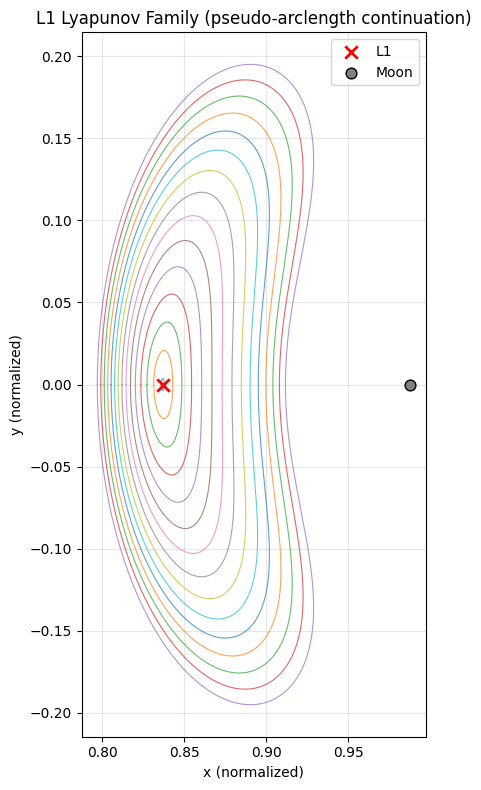

In [14]:
# notebook cell — plot the L1 family
import matplotlib.pyplot as plt

lps = find_lagrange_points(mu)
fig, ax = plt.subplots(figsize=(10, 8))
step = 4
for i in range(0, len(L1_family), step):
    o = L1_family[i]
    sol = solve_ivp(cr3bp_rhs, (0, o['period']), o['state0'], args=(mu,),
                    method='DOP853', rtol=1e-11, atol=1e-11,
                    t_eval=np.linspace(0, o['period'], 400))
    ax.plot(sol.y[0], sol.y[1], linewidth=0.8, alpha=0.7)

ax.scatter([lps['L1'][0]], [0], color='red', s=80, marker='x', zorder=5,
           linewidth=2, label='L1')
ax.scatter([1 - mu], [0], color='gray', s=60, zorder=5, edgecolor='black', label='Moon')
ax.set_aspect('equal')
ax.set_xlabel('x (normalized)')
ax.set_ylabel('y (normalized)')
ax.set_title('L1 Lyapunov Family (pseudo-arclength continuation)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

State dimension: 4 (should be 4 — planar, no z)
Orbit 55: x range [0.7976, 0.9273], y range [-0.1927, 0.1927]


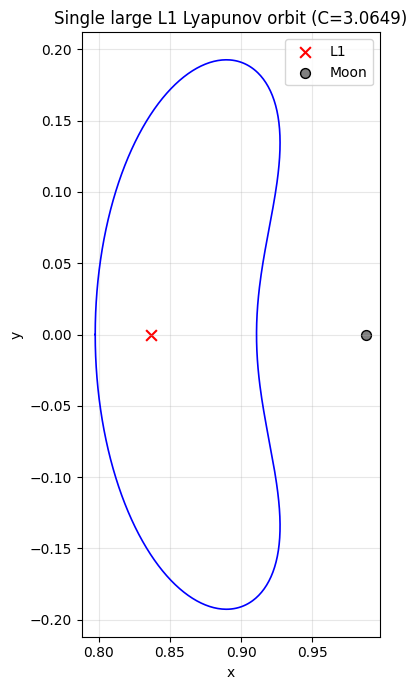

In [15]:
# Confirm orbits are planar (no z) and look at a large one's actual shape
o = L1_family[55]  # a large orbit
sol = solve_ivp(cr3bp_rhs, (0, o['period']), o['state0'], args=(mu,),
                method='DOP853', rtol=1e-11, atol=1e-11,
                t_eval=np.linspace(0, o['period'], 500))

print(f"State dimension: {len(o['state0'])} (should be 4 — planar, no z)")
print(f"Orbit 55: x range [{sol.y[0].min():.4f}, {sol.y[0].max():.4f}], "
      f"y range [{sol.y[1].min():.4f}, {sol.y[1].max():.4f}]")

# Plot just this one orbit, clean 2D
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(sol.y[0], sol.y[1], 'b-', linewidth=1.2)
ax.scatter([lps['L1'][0]], [0], color='red', s=60, marker='x', label='L1')
ax.scatter([1-mu], [0], color='gray', s=50, edgecolor='black', label='Moon')
ax.set_aspect('equal')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title(f'Single large L1 Lyapunov orbit (C={o["jacobi"]:.4f})')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# notebook cell — get a starting L2 Lyapunov orbit, then continue the family
from cr3bp import cr3bp_jacobian
from orbits import correct_lyapunov_orbit  # your original single-orbit corrector

# --- Linearized guess at L2 (same method as you used for L1) ---
L2_state = [lps['L2'][0], 0.0, 0.0, 0.0]
A_L2 = cr3bp_jacobian(L2_state, mu)
eigvals, eigvecs = np.linalg.eig(A_L2)

# Find the imaginary eigenvalue pair (the Lyapunov oscillation)
imag_idx = np.argmax(eigvals.imag)
omega_L2 = eigvals[imag_idx].imag
v_L2 = eigvecs[:, imag_idx]
ratio_L2 = v_L2[3].real / v_L2[0].real   # vy0/delta_x ratio

print(f"L2 omega = {omega_L2:.6f}, linear period = {2*np.pi/omega_L2:.6f}")
print(f"L2 ratio vy0/delta_x = {ratio_L2:.6f}")

# Small starting orbit near L2
delta_x_L2 = -0.001
x0_L2 = lps['L2'][0] + delta_x_L2
vy0_guess_L2 = ratio_L2 * delta_x_L2

# Correct it to a real periodic orbit (your original corrector with the guard)
vy0_L2, half_period_L2, crossing_L2 = correct_lyapunov_orbit(
    x0_L2, vy0_guess_L2, mu, verbose=True)

X_start_L2 = np.array([x0_L2, vy0_L2, half_period_L2])
print(f"\nStarting L2 orbit: {X_start_L2}")

# --- Now run the SAME pseudo-arclength machinery, just from the L2 start ---
F0_L2, dF0_L2, _ = periodicity_constraint(X_start_L2, mu)
t0_L2 = family_tangent(dF0_L2)

L2_family = compute_family_pseudo_arclength(
    X_start_L2, ds=0.01, n_orbits=60, mu=mu, initial_direction=t0_L2)

print(f"\nComputed {len(L2_family)} L2 orbits")
jacobis_L2 = [o['jacobi'] for o in L2_family]
print(f"L2 Jacobi range: {min(jacobis_L2):.4f} to {max(jacobis_L2):.4f}")

L2 omega = 1.862646, linear period = 3.373258
L2 ratio vy0/delta_x = -5.425150
  iter 0: vy0=0.005425150017, residual vx=2.309e-04
  iter 1: vy0=0.005405288081, residual vx=-5.356e-06
  iter 2: vy0=0.005405728017, residual vx=-2.841e-09
  iter 3: vy0=0.005405728251, residual vx=-3.794e-15
  Converged: vx residual -3.79e-15

Starting L2 orbit: [1.15468217 0.00540573 1.68664966]
  Orbit 0: x0=1.15468, vy0=0.00541, C=3.17214, T=3.37330
  Orbit 10: x0=1.13553, vy0=0.10322, C=3.16480, T=3.38773
  Orbit 20: x0=1.11553, vy0=0.19907, C=3.14711, T=3.42764
  Orbit 30: x0=1.09619, vy0=0.29124, C=3.12368, T=3.49442
  Orbit 40: x0=1.07892, vy0=0.37776, C=3.09900, T=3.58818
  Orbit 50: x0=1.06444, vy0=0.45745, C=3.07619, T=3.70525

Computed 60 L2 orbits
L2 Jacobi range: 3.0583 to 3.1721


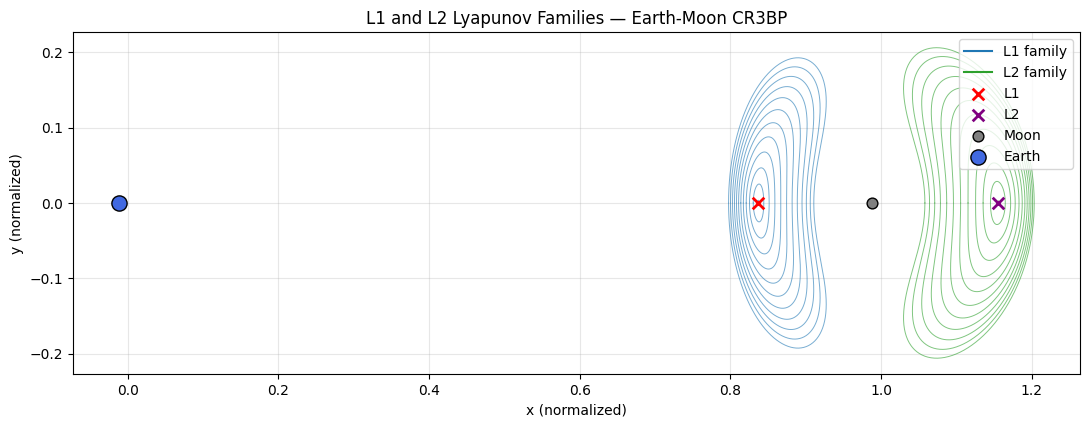

In [17]:
# notebook cell — plot both L1 and L2 families together
fig, ax = plt.subplots(figsize=(11, 8))

step = 5
for fam, color, label in [(L1_family, 'tab:blue', 'L1 family'),
                           (L2_family, 'tab:green', 'L2 family')]:
    for i in range(0, len(fam), step):
        o = fam[i]
        sol = solve_ivp(cr3bp_rhs, (0, o['period']), o['state0'], args=(mu,),
                        method='DOP853', rtol=1e-11, atol=1e-11,
                        t_eval=np.linspace(0, o['period'], 400))
        ax.plot(sol.y[0], sol.y[1], color=color, linewidth=0.7, alpha=0.6)
    # label only once per family
    ax.plot([], [], color=color, label=label)

ax.scatter([lps['L1'][0]], [0], color='red', s=70, marker='x', zorder=5, linewidth=2, label='L1')
ax.scatter([lps['L2'][0]], [0], color='purple', s=70, marker='x', zorder=5, linewidth=2, label='L2')
ax.scatter([1-mu], [0], color='gray', s=60, zorder=5, edgecolor='black', label='Moon')
ax.scatter([-mu], [0], color='royalblue', s=120, zorder=5, edgecolor='black', label='Earth')
ax.set_aspect('equal')
ax.set_xlabel('x (normalized)'); ax.set_ylabel('y (normalized)')
ax.set_title('L1 and L2 Lyapunov Families — Earth-Moon CR3BP')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()